# 01 - Scenario di riferimento: pasto non annunciato (adult#001, 60 g)

**Scenario.** Paziente virtuale `adult#001` (simglucose, modello UVA/Padova), sensore Dexcom, pompa Insulet. Simulazione di 16 ore (320 passi da 3 minuti, dalle 08:00 alle 24:00). Un pasto da 60 g di carboidrati, **non annunciato**, viene assunto alle ore 12:00 (4 ore dopo l'inizio).

**Controllori confrontati** (codice in `aid_sim.py`):
1. **PID**: azione diretta, `u = u_b + Kp e + Ki I + Kd de/dt`, con anti-windup per clamping dell'integrale e saturazione `0 <= u <= 0.25 U/min`.
2. **PID + IOB + PLGS** (proposto): stesso PID, con in più (a) un tetto sull'insulina attiva stimata `IOB = S1 + S2` (tetto = 1.5 x fabbisogno basale orario) e (b) la sospensione predittiva dell'infusione (PLGS: proiezione a 20 min sotto 90 mg/dL o misura sotto 75 mg/dL).

**Metriche** (sulla glicemia plasmatica): TIR (70-180 mg/dL), TAR (>180), TBR (<70), picco, nadir, TBR tardivo (ipoglicemia da 3 ore dopo il pasto a fine simulazione).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import aid_sim as A
pd.set_option('display.width', 200)

## Parametri
Guadagni e soglie usati (valori di default di `AIDController`).

In [2]:
import inspect
sig = inspect.signature(A.AIDController.__init__)
params = {k: v.default for k, v in sig.parameters.items() if v.default is not inspect.Parameter.empty}
print("Parametri del controllore:", params)
print("Pasto non annunciato: 60 g, offset", A.MEAL_OFFSET_H, "h dall'inizio (ore 12:00)")

Parametri del controllore: {'target': 120.0, 'kp': 0.0001, 'ki': 5e-06, 'kd': 0.002, 'i_min': -2000.0, 'i_max': 10000.0, 'use_iob': False, 'use_plgs': False, 'iob_alpha': 1.5, 'tau_s': 50.0, 't_pred': 20.0, 'plgs_pred': 90.0, 'plgs_now': 75.0}
Pasto non annunciato: 60 g, offset 4.0 h dall'inizio (ore 12:00)


## Simulazione

In [3]:
df_pid, ub = A.simulate('adult#001', 60.0, {})
df_prop, _ = A.simulate('adult#001', 60.0, dict(use_iob=True, use_plgs=True))
print("Fabbisogno basale adult#001: %.3f U/h" % (ub*60))

Fabbisogno basale adult#001: 1.267 U/h


## Grafici: glicemia, insulina somministrata, IOB

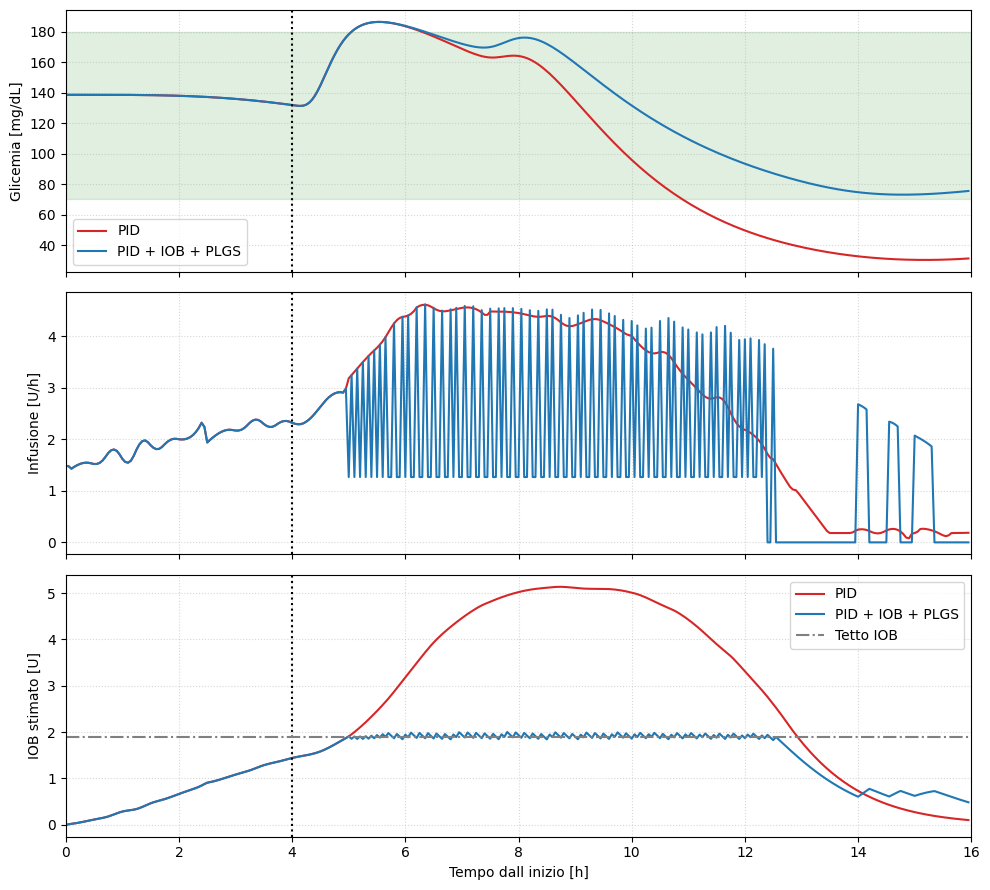

In [4]:
fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for df, lab, col in [(df_pid, 'PID', 'tab:red'), (df_prop, 'PID + IOB + PLGS', 'tab:blue')]:
    ax[0].plot(df.t_h, df.BG, color=col, label=lab)
    ax[1].plot(df.t_h, df.Insulin_Uh, color=col)
    ax[2].plot(df.t_h, df.IOB, color=col, label=lab)
for a in ax: a.axvline(A.MEAL_OFFSET_H, color='k', ls=':')
ax[0].axhspan(70, 180, color='green', alpha=.12); ax[0].set_ylabel('Glicemia [mg/dL]'); ax[0].legend()
ax[1].set_ylabel('Infusione [U/h]')
ax[2].axhline(1.5*ub*60, color='gray', ls='-.', label='Tetto IOB'); ax[2].set_ylabel('IOB stimato [U]'); ax[2].legend()
ax[2].set_xlabel('Tempo dall inizio [h]'); ax[2].set_xlim(0, 16)
for a in ax: a.grid(ls=':', alpha=.5)
plt.tight_layout(); plt.show()

## Indicatori

In [5]:
rows = []
for df, lab in [(df_pid, 'PID'), (df_prop, 'PID + IOB + PLGS')]:
    m = A.metrics(df); m['TBR_tardivo'] = 100*np.mean(df[df.t_h >= A.MEAL_OFFSET_H+3].BG.values < 70)
    rows.append({'Controllore': lab, **{k: round(float(v), 1) for k, v in m.items()}})
pd.DataFrame(rows)

,Controllore,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,picco,nadir
0,PID,60.6,7.5,0.0,31.9,26.6,56.7,186.3,30.4
1,PID + IOB + PLGS,92.2,7.8,0.0,0.0,0.0,0.0,186.3,73.1


## Lettura dei risultati
Il picco postprandiale è praticamente lo stesso per i due controllori: con ritardi di misura e di assorbimento dell'insulina nessuno dei due può evitarlo. La differenza compare dopo: il PID accumula insulina nel sottocute (IOB fino a circa 5 U) e va in ipoglicemia, il controllore con tetto sull'IOB la limita. Il tetto agisce però con un comportamento a commutazione (l'infusione alterna tra valore basale e valore alto), che è un limite da discutere nella tesi.